# Double Tube-Preserving Regularization (DTR): main paper

Implementation of *"Double Tube-Preserving Regularization for Robust Visual Data Recovery"* (Wang, Wang, Wang, He, Hu, Li, Tang), Neurocomputing manuscript **NEUCOM-D-26-21531**.

| Paper | Notebook section |
|---|---|
| §2 Notations and preliminaries (Defs. 1–6) | 2 |
| §3.1 Motivation, Def. 7 (unfolding singular value matrix), Figs. 2–4 | 3 |
| §3.2 T2NN (Def. 8), T2L1 (Def. 9), the DTR model (Eq. 10) | 4 |
| §3.3 Optimization, Algorithm 1, the rule for τ_L and τ_E | 5 |
| §4.1 Color image recovery (Fig. 6, Tabs. 2–4) | 6 |
| §4.2 Hyperspectral image restoration (Fig. 7) | 7 |
| §4.3 Video denoising (Tab. 5, Fig. 8) and §4.4 ablation (Tab. 6) | 8 |
| §4.4 Parameter analysis (Fig. 9) and a γ_E sensitivity check | 9 |
| §4.5 Background modeling (Fig. 10) | 10 |
| Summary: paper vs. this implementation | 11 |

The supplementary material is in `02_DTR_supplementary.ipynb`: the proof of Theorem 1, the convergence analysis, GDTR (Algorithm 2) and the extra BSD experiment.

**Methods.** This notebook implements the methods that follow directly from the paper:
- **TRPCA**: Algorithm 1 with both adaptive weightings switched off, which is exactly TNN + ℓ1.
- **DTR-L / DTR-E**: the ablation variants of Tab. 6.
- **DTR**: the full model.
- **RPCA**: matrix RPCA, used only for background modeling.

The other baselines (ETRPCA, BTRTF, t-SWP, SRPCA, BTPCA, SNN) come from separate papers and are not reimplemented. Their published numbers appear only in the comparison tables. GDTR and t-CTV are in notebook 02.

**Data.** BSDS500 and the QCIF YUV sequences (Akiyo, Claire, Container, News, Hall Monitor) are downloaded to `data/` on first run, about 130 MB. PaviaU (§4.2) and CAVIAR1 (§4.5) have no stable public download:
- §7 uses `data/PaviaU.mat` if you place it there; otherwise it uses a synthetic hyperspectral cube.
- §10 uses Hall Monitor instead of CAVIAR1.

**Runtime.** About 30 minutes with the default subset sizes on a 16-core machine. The knobs `N_PER_SPLIT`, `N_RATIO_IMAGES` and `N_FRAMES` control the size of each experiment.

## 1. Setup

In [1]:
import os
# The per-slice SVDs here are small, so single-threaded BLAS is as fast or faster;
# experiments are parallelised across worker processes instead (see run_parallel).
# This must run before numpy is imported - restart the kernel if numpy was already loaded.
for _v in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(_v, '1')

import tarfile
import time
import urllib.request
import warnings
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path('data')
N_JOBS = max(1, min(12, (os.cpu_count() or 2) - 2))   # worker processes for independent runs
SEED = 0
plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'gray', 'axes.grid': False})
pd.set_option('display.precision', 2)
print(f'numpy {np.__version__} | N_JOBS = {N_JOBS}')

numpy 2.4.4 | N_JOBS = 12


In [2]:
BSDS_URL = 'https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/grouping/BSR/BSR_bsds500.tgz'
YUV_URL = 'https://media.xiph.org/video/derf/y4m/{}_qcif.y4m'


def ensure_bsds(root=DATA_DIR):
    """Download BSDS500 (~70 MB) once; keeps only the 500 JPEGs in data/BSDS500/{train,val,test}."""
    out = root / 'BSDS500'
    if out.exists():
        return out
    root.mkdir(parents=True, exist_ok=True)
    tgz = root / 'BSR_bsds500.tgz'
    print('downloading BSDS500 ...')
    urllib.request.urlretrieve(BSDS_URL, tgz)
    prefix = 'BSR/BSDS500/data/images/'
    with tarfile.open(tgz) as tf:
        for m in tf.getmembers():
            if m.isfile() and m.name.startswith(prefix) and m.name.endswith('.jpg'):
                m.name = m.name[len(prefix):]
                tf.extract(m, out, filter='data')
    tgz.unlink()
    return out


def ensure_yuv(name, root=DATA_DIR):
    """Download a QCIF (176x144) test sequence from the Xiph derf collection."""
    path = root / 'yuv' / f'{name}_qcif.y4m'
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        print(f'downloading {name} ...')
        urllib.request.urlretrieve(YUV_URL.format(name), path)
    return path


def read_y4m(path, n_frames=None, rgb=False):
    """Minimal YUV4MPEG2 4:2:0 reader -> floats in [0, 1].
    Returns the luma as (H, W, T), or BT.601 RGB as (H, W, 3, T) if rgb=True."""
    data = Path(path).read_bytes()
    end = data.index(b'\n')
    hdr = {tok[:1]: tok[1:] for tok in data[:end].split()[1:]}
    W, H = int(hdr[b'W']), int(hdr[b'H'])
    ysz, csz = W * H, (W // 2) * (H // 2)
    pos, frames = end + 1, []
    while pos < len(data) and (n_frames is None or len(frames) < n_frames):
        pos = data.index(b'\n', pos) + 1                          # skip the 'FRAME' line
        Y = np.frombuffer(data, np.uint8, ysz, pos).reshape(H, W).astype(float)
        if rgb:
            U, V = (np.kron(np.frombuffer(data, np.uint8, csz, pos + ysz + i * csz)
                            .reshape(H // 2, W // 2).astype(float), np.ones((2, 2))) - 128 for i in (0, 1))
            Yl = 1.164 * (Y - 16)
            rgb_frame = np.stack([Yl + 1.596 * V, Yl - 0.392 * U - 0.813 * V, Yl + 2.017 * U], axis=-1)
            frames.append(np.clip(rgb_frame / 255, 0, 1))
        else:
            frames.append(Y / 255)
        pos += ysz + 2 * csz
    return np.stack(frames, axis=-1)


def load_image(path):
    return np.asarray(Image.open(path).convert('RGB'), dtype=np.float64) / 255.0


def psnr(x, ref):
    """PSNR (dB) over the whole tensor for data in [0, 1]; the estimate is clipped to [0, 1] first."""
    return 10 * np.log10(1.0 / np.mean((np.clip(x, 0, 1) - ref) ** 2))


def tube_corrupt(X, ratio, rng):
    """Tube-wise corruption used throughout Sec. 4: a fraction `ratio` of the (i, j) positions is
    replaced by random values from [0, 255] (scaled to [0, 1]) in *every* frontal slice."""
    d1, d2, d3 = X.shape
    idx = rng.choice(d1 * d2, int(round(ratio * d1 * d2)), replace=False)
    Y = X.reshape(d1 * d2, d3).copy()
    Y[idx] = rng.integers(0, 256, (idx.size, d3)) / 255.0
    mask = np.zeros(d1 * d2, bool)
    mask[idx] = True
    return Y.reshape(d1, d2, d3), mask.reshape(d1, d2)


def run_parallel(fn, jobs, n_jobs=None):
    """Map fn over jobs in forked worker processes (order preserved); plain loop if fork is unavailable."""
    n_jobs = N_JOBS if n_jobs is None else n_jobs
    if n_jobs > 1 and len(jobs) > 1 and 'fork' in mp.get_all_start_methods():
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', DeprecationWarning)   # "process is multi-threaded, fork() ..."
            with ProcessPoolExecutor(min(n_jobs, len(jobs)), mp_context=mp.get_context('fork')) as ex:
                return list(ex.map(fn, jobs))
    return [fn(j) for j in jobs]


bsds = ensure_bsds()
TEST_FILES = sorted((bsds / 'test').glob('*.jpg'))
EXAMPLES = TEST_FILES[:6]          # example images for Fig. 6 / Tab. 2 (the paper does not name its six)
print('BSDS500 images:', {s: len(list((bsds / s).glob('*.jpg'))) for s in ('train', 'val', 'test')})

BSDS500 images: {'train': 200, 'val': 100, 'test': 200}


## 2. Notations and preliminaries (paper §2)

The paper uses the t-product framework of Kilmer & Martin. The definitions are implemented literally below, then checked against the FFT shortcut that every algorithm actually uses: `bcirc` is block-diagonalised by the DFT along mode 3, so all t-SVD work reduces to independent matrix SVDs of the Fourier-domain frontal slices $\bar{\mathcal X}^{(k)}$.

In [3]:
def unfold(T):
    """Def. 1 - stack the frontal slices vertically: (d1*d3) x d2."""
    return np.concatenate([T[:, :, k] for k in range(T.shape[2])], axis=0)


def fold(M, shape):
    d1, _, d3 = shape
    return np.stack([M[k * d1:(k + 1) * d1] for k in range(d3)], axis=2)


def bcirc(T):
    """Def. 2 - block circulant matrix (d1*d3) x (d2*d3); block (i, j) is T^((i - j) mod d3)."""
    d3 = T.shape[2]
    return np.block([[T[:, :, (i - j) % d3] for j in range(d3)] for i in range(d3)])


def tprod_bcirc(A, B):
    """Def. 3 - t-product A * B = fold(bcirc(A) . unfold(B)), computed literally."""
    return fold(bcirc(A) @ unfold(B), (A.shape[0], B.shape[1], A.shape[2]))


def tprod(A, B):
    """The same t-product as slice-wise matrix products in the Fourier domain."""
    Af, Bf = np.fft.fft(A, axis=2), np.fft.fft(B, axis=2)
    return np.real(np.fft.ifft(np.einsum('ijk,jlk->ilk', Af, Bf), axis=2))


def ttrans(T):
    """Tensor transpose T^*: transpose every frontal slice and reverse the order of slices 2..d3."""
    return np.concatenate([T[:, :, :1], T[:, :, :0:-1]], axis=2).transpose(1, 0, 2)


def tsvd(X):
    """Def. 4 - full t-SVD X = U * S * V^* from the SVDs of the Fourier-domain slices.
    Slice 0 (and slice d3/2 for even d3) is real, and the rest come in conjugate pairs, so U, S, V are real."""
    d1, d2, d3 = X.shape
    Xf = np.fft.fft(X, axis=2)
    Uf, Sf, Vf = (np.zeros(s, complex) for s in ((d1, d1, d3), (d1, d2, d3), (d2, d2, d3)))
    r = np.arange(min(d1, d2))
    for k in range(d3 // 2 + 1):
        A = Xf[:, :, k].real if k == 0 or 2 * k == d3 else Xf[:, :, k]
        u, s, vh = np.linalg.svd(A)
        Uf[:, :, k], Vf[:, :, k] = u, vh.conj().T
        Sf[r, r, k] = s
    for k in range(d3 // 2 + 1, d3):
        Uf[:, :, k], Sf[:, :, k], Vf[:, :, k] = (T[:, :, d3 - k].conj() for T in (Uf, Sf, Vf))
    U, S, V = (np.real(np.fft.ifft(T, axis=2)) for T in (Uf, Sf, Vf))
    return U, S, V


def tubal_rank(X, rtol=1e-10):
    """Def. 5 - number of nonzero singular tubes S(l, l, :)."""
    _, S, _ = tsvd(X)
    r = np.arange(min(X.shape[:2]))
    tubes = np.linalg.norm(S[r, r, :], axis=1)
    return int((tubes > rtol * tubes.max()).sum())

In [4]:
def svd_unfold(X):
    """Def. 7 - unfolding singular value matrix Sigma+ (d x d3): column k holds the singular
    values of the k-th Fourier-domain frontal slice, so row l is the l-th singular tube."""
    Xf = np.fft.fft(X, axis=2)
    return np.linalg.svd(np.moveaxis(Xf, 2, 0), compute_uv=False).T


def tnn(X):
    """Def. 6 - tensor nuclear norm (1/d3) sum_k ||Xbar^(k)||_* = (1/d3) ||Sigma+||_1."""
    return svd_unfold(X).sum() / X.shape[2]

In [5]:
rng = np.random.default_rng(SEED)
A, B = rng.standard_normal((5, 3, 4)), rng.standard_normal((3, 6, 4))
X = tprod(A, B)                                       # tubal rank <= 3 by construction
U, S, V = tsvd(X)
I5 = np.zeros((5, 5, 4)); I5[:, :, 0] = np.eye(5)
offdiag = S * (1 - np.eye(5, 6))[:, :, None]
Sig = svd_unfold(X)

checks = {
    'Def. 3: bcirc t-product == FFT t-product': np.abs(tprod_bcirc(A, B) - tprod(A, B)).max(),
    'Def. 4: ||U*S*V^T - X||_max': np.abs(tprod(tprod(U, S), ttrans(V)) - X).max(),
    'Def. 4: ||U^T*U - I||_max (orthogonal)': np.abs(tprod(ttrans(U), U) - I5).max(),
    'Def. 4: S is f-diagonal (max off-diagonal)': np.abs(offdiag).max(),
    'Def. 6: TNN - (1/d3)||Sigma+||_1': tnn(X) - Sig.sum() / 4,
    'Def. 6: TNN - (1/d3) sum_k ||Xbar^(k)||_*': tnn(X) - sum(np.linalg.norm(np.fft.fft(X, axis=2)[:, :, k], 'nuc') for k in range(4)) / 4,
}
display(pd.Series(checks).map('{:.2e}'.format).to_frame('value'))
print('tubal rank (Def. 5):', tubal_rank(X),
      '| nonzero rows of Sigma+ (Sec. 3.1):', int((np.linalg.norm(Sig, axis=1) > 1e-10 * Sig.max()).sum()))

,value
Def. 3: bcirc t-product == FFT t-product,1.78e-15
Def. 4: ||U*S*V^T - X||_max,1.15e-14
Def. 4: ||U^T*U - I||_max (orthogonal),7.22e-16
Def. 4: S is f-diagonal (max off-diagonal),0.00e+00
Def. 6: TNN - (1/d3)||Sigma+||_1,0.00e+00
Def. 6: TNN - (1/d3) sum_k ||Xbar^(k)||_*,0.00e+00


tubal rank (Def. 5): 3 | nonzero rows of Sigma+ (Sec. 3.1): 3


## 3. Motivation: tube-sparse structure (paper §3.1, Figs. 2–4)

**Def. 7.** The unfolding singular value matrix $\Sigma^+\in\mathbb R^{d\times d_3}$ has entries $\Sigma^+_{lk}=\sigma_l(\bar{\mathcal X}^{(k)})$, so row $l$ is the $l$-th singular tube. Two facts follow:
- $\|\mathcal X\|_* = \frac1{d_3}\|\Sigma^+\|_1$, so TNN treats every singular value independently.
- The tubal rank is the number of nonzero rows of $\Sigma^+$, so a low tubal rank means $\Sigma^+$ is joint row-sparse.

The same tube-wise structure appears in the corruption: in a color image all three channels are hit at the same pixel.

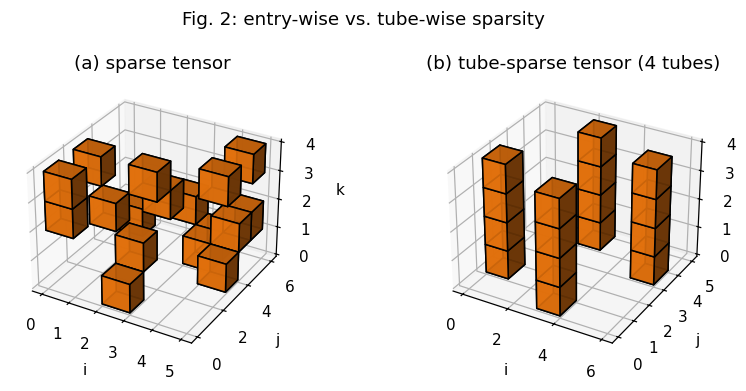

In [6]:
rng = np.random.default_rng(SEED)
sparse_vox = rng.random((6, 6, 4)) < 0.12
tube_vox = np.zeros((6, 6, 4), bool)
for i, j in [(0, 1), (2, 4), (3, 0), (5, 3)]:
    tube_vox[i, j, :] = True
fig = plt.figure(figsize=(8, 3.4))
for n, (title, vox) in enumerate([('(a) sparse tensor', sparse_vox), ('(b) tube-sparse tensor (4 tubes)', tube_vox)]):
    ax = fig.add_subplot(1, 2, n + 1, projection='3d')
    ax.voxels(vox, facecolors='tab:orange', edgecolor='k', alpha=0.9)
    ax.set(title=title, xlabel='i', ylabel='j', zlabel='k')
plt.suptitle('Fig. 2: entry-wise vs. tube-wise sparsity')
plt.tight_layout(); plt.show()

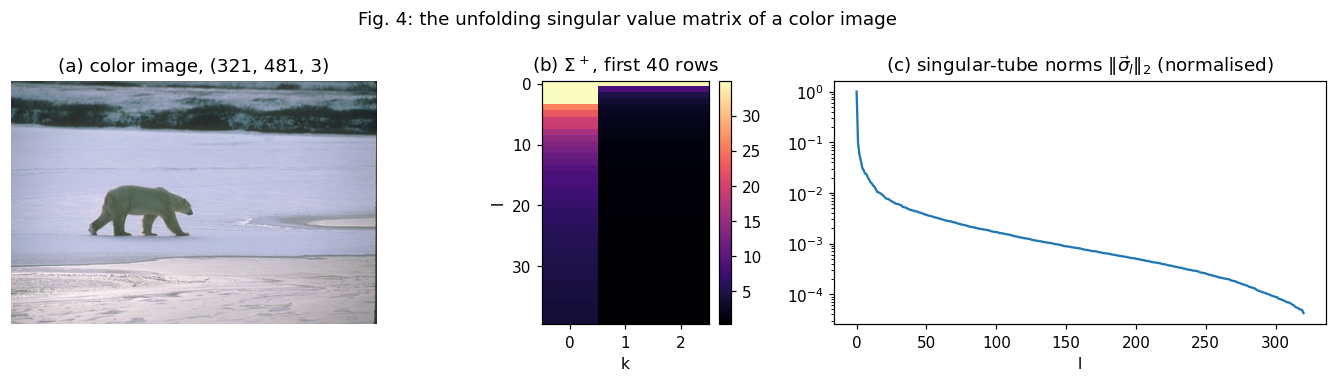

Sigma+ is (321, 3); first 40 tubes hold 99.94% of the energy, tube 40 is 4.6e-03 of tube 1, and the smallest is 4.2e-05.


In [7]:
img0 = load_image(EXAMPLES[0])
Sig0 = svd_unfold(img0)
tubes0 = np.linalg.norm(Sig0, axis=1)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5), gridspec_kw={'width_ratios': [1.4, 0.55, 1.3]})
ax[0].imshow(img0); ax[0].set_title(f'(a) color image, {img0.shape}'); ax[0].axis('off')
im = ax[1].imshow(Sig0[:40], aspect='auto', cmap='magma', vmax=np.percentile(Sig0[:40], 97))
ax[1].set(title='(b) $\\Sigma^+$, first 40 rows', xlabel='k', ylabel='l', xticks=range(3)); fig.colorbar(im, ax=ax[1])
ax[2].semilogy(tubes0 / tubes0[0]); ax[2].set(title='(c) singular-tube norms $\\|\\vec\\sigma_l\\|_2$ (normalised)', xlabel='l')
plt.suptitle('Fig. 4: the unfolding singular value matrix of a color image'); plt.tight_layout(); plt.show()
energy = np.cumsum(tubes0 ** 2) / np.sum(tubes0 ** 2)
print(f'Sigma+ is {Sig0.shape}; first 40 tubes hold {100 * energy[39]:.2f}% of the energy, '
      f'tube 40 is {tubes0[39] / tubes0[0]:.1e} of tube 1, and the smallest is {tubes0[-1] / tubes0[0]:.1e}.')

Fig. 4 says the rows of $\Sigma^+$ past 40 are "all zero vectors". That is only approximately true for a real photo: the tube norms decay by several orders of magnitude, but they are not exactly zero. The image is *approximately* low tubal rank, and that is the regime in which the adaptive weights matter. Large tubes should be shrunk less, small ones more.

## 4. T2NN, T2L1 and the DTR model (paper §3.2)

Both regularisers use the structure function $f(x)=1/(1+x/\tau)$, evaluated on the $\ell_2$ norm of a whole tube and applied to every entry of that tube:

$$\|\mathcal X\|_{T,*}=\frac1{d_3}\sum_{l=1}^{d} f_L\big(\|\vec\sigma_l(\bar{\mathcal X})\|_2\big)\sum_{k=1}^{d_3}\sigma_l(\bar{\mathcal X}^{(k)})\quad\text{(Def. 8)},\qquad
\|\mathcal E\|_{T,1}=\sum_{i,j} f_E\big(\|\mathcal E(i,j,:)\|_2\big)\sum_{k}|\mathcal E_{ijk}|\quad\text{(Def. 9)}.$$

The DTR model (Eq. 10) is then

$$\min_{\mathcal L,\mathcal E}\ \|\mathcal L\|_{T,*}+\lambda\|\mathcal E\|_{T,1}\quad\text{s.t.}\quad\mathcal X=\mathcal L+\mathcal E.$$

With $\tau\to\infty$, $f\equiv1$ and the two regularisers reduce to TNN and the ℓ1 norm.

In [8]:
def structure_fn(x, tau):
    """Structure function f(x) = 1 / (1 + x / tau) shared by T2NN (f_L) and T2L1 (f_E)."""
    return 1.0 / (1.0 + x / tau)


def structure_weights(tube_norms, gamma):
    """Adaptive weights f(||tube||_2) with tau = gamma * mean(||tube||_2) (Sec. 3.3, Parameter Analysis).
    Before any tube is nonzero (e.g. E = 0 in the first iterations) tau = 0 and all weights are 1."""
    tau = gamma * tube_norms.mean()
    return np.ones_like(tube_norms) if tau == 0 else structure_fn(tube_norms, tau)

In [9]:
def t2nn(X, tau_L):
    """Def. 8 - tube-preserving tensor nuclear norm."""
    Sig = svd_unfold(X)
    return (structure_fn(np.linalg.norm(Sig, axis=1), tau_L) * Sig.sum(axis=1)).sum() / X.shape[2]


def t2l1(E, tau_E):
    """Def. 9 - tube-preserving tensor l1 norm."""
    return (structure_fn(np.linalg.norm(E, axis=2), tau_E) * np.abs(E).sum(axis=2)).sum()

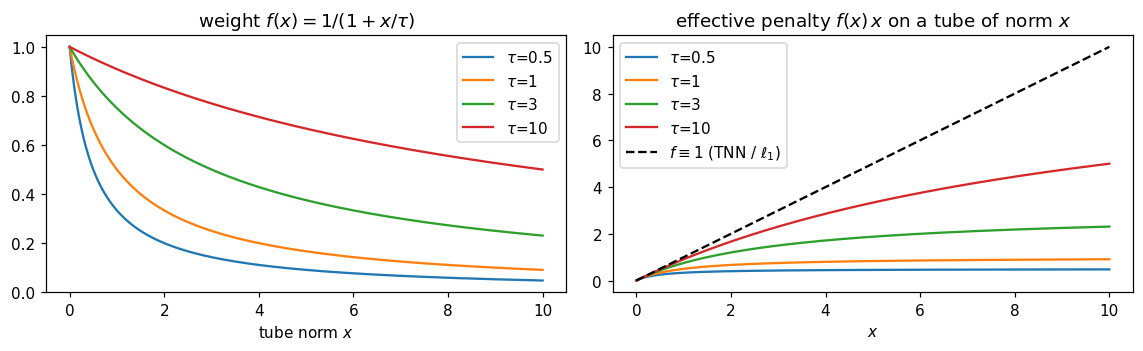

,l1,T2L1 (tau_E = 1)
tube-sparse noise,7420.0,1355.96
entry-sparse noise,7420.0,2830.08


In [10]:
x = np.linspace(0, 10, 400)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.3))
for tau in (0.5, 1, 3, 10):
    ax[0].plot(x, structure_fn(x, tau), label=f'$\\tau$={tau}')
    ax[1].plot(x, structure_fn(x, tau) * x, label=f'$\\tau$={tau}')
ax[1].plot(x, x, 'k--', label='$f\\equiv1$ (TNN / $\\ell_1$)')
ax[0].set(title='weight $f(x)=1/(1+x/\\tau)$', xlabel='tube norm $x$'); ax[0].legend()
ax[1].set(title='effective penalty $f(x)\\,x$ on a tube of norm $x$', xlabel='$x$'); ax[1].legend()
plt.tight_layout(); plt.show()

# T2L1 prefers tube-structured noise: same l1 mass, arranged as tubes vs. scattered entries
rng = np.random.default_rng(SEED)
d1, d2, d3 = 60, 60, 20
E_tube = np.zeros((d1, d2, d3)); E_tube[rng.random((d1, d2)) < 0.1] = 1.0
E_scat = np.zeros(d1 * d2 * d3); E_scat[rng.choice(E_scat.size, int(E_tube.sum()), replace=False)] = 1.0
E_scat = E_scat.reshape(d1, d2, d3)
display(pd.DataFrame({'l1': [np.abs(E).sum() for E in (E_tube, E_scat)],
                      'T2L1 (tau_E = 1)': [t2l1(E, 1.0) for E in (E_tube, E_scat)]},
                     index=['tube-sparse noise', 'entry-sparse noise']))

The penalty $f(x)\,x = x\tau/(\tau+x)$ saturates at $\tau$: large tubes, meaning dominant singular tubes or strong noise tubes, are barely penalised beyond $\tau$. For the same ℓ1 mass, T2L1 is much smaller when the mass is arranged in tubes. This is the "tube-preserving" behaviour.

## 5. Optimization: Algorithm 1 (paper §3.3)

ADMM on the augmented Lagrangian (Eq. 11). The weights are frozen inside each subproblem and refreshed after it (Step 3):

1. $\mathcal L^{t+1}=\mathrm{prox}_{\|\cdot\|_{T,*}}(\mathcal X-\mathcal E^t-\mathcal N^t/\mu^t)$ with $\tau=1/\mu^t$. By Theorem 1 this is the slice-wise weighted SVT $(\bar S^{(k)}_{ll}-\tau w_l)_+$. The theorem needs $0\le w_1\le\dots\le w_d$; it holds automatically here, because tube norms decrease with $l$ and $f$ is decreasing.
2. $\mathcal E^{t+1}=\mathcal Q(\mathcal K^t,\tfrac{\lambda}{\mu^t}W^t)$: tube-wise weighted soft-thresholding.
3. $w_l=f_L(\|\vec\sigma_l(\bar{\mathcal L}^{t+1})\|_2)$ and $W_{ij}=f_E(\|\mathcal E^{t+1}(i,j,:)\|_2)$, with $\tau_L=\gamma_L\,\mathrm{mean}_l\|\vec\sigma_l\|_2$ and $\tau_E=\gamma_E\,\mathrm{mean}_{ij}\|\mathcal E(i,j,:)\|_2$.
4. $\mathcal N^{t+1}=\mathcal N^t+\mu^t(\mathcal L^{t+1}+\mathcal E^{t+1}-\mathcal X)$ and $\mu^{t+1}=\rho\mu^t$.

Paper settings: $\mu^0=10^{-2}$, $\rho=1.1$, $\epsilon=10^{-6}$ (ℓ∞ stopping rule), $\lambda=1/\sqrt{d_3\max(d_1,d_2)}$, $\gamma_L=3$, $\gamma_E=10^3$. Data are scaled to $[0,1]$.

In [11]:
def t2nn_prox(M, tau, w):
    """Proximal operator of the T2NN, Eq. (13): U * ifft(P_{tau w}(S_bar), [], 3) * V^*.
    Each Fourier slice is shrunk by (S_ll - tau * w_l)_+. Only the first floor(d3/2)+1 slices are
    decomposed; the rest follow from conjugate symmetry of the DFT of a real tensor.
    Returns the minimiser L and its unfolding singular value matrix Sigma+ (d x d3)."""
    d1, d2, d3 = M.shape
    Mf = np.fft.fft(M, axis=2)
    half = d3 // 2 + 1
    U, s, Vh = np.linalg.svd(np.moveaxis(Mf[:, :, :half], 2, 0), full_matrices=False)
    s = np.maximum(s - tau * w[None, :], 0.0)
    Lf = np.empty_like(Mf)
    Lf[:, :, :half] = np.moveaxis((U * s[:, None, :]) @ Vh, 0, 2)
    Sig = np.empty((s.shape[1], d3))
    Sig[:, :half] = s.T
    if d3 > 1:
        Lf[:, :, half:] = np.conj(Lf[:, :, 1:d3 - half + 1][:, :, ::-1])
        Sig[:, half:] = Sig[:, 1:d3 - half + 1][:, ::-1]
    return np.real(np.fft.ifft(Lf, axis=2)), Sig


def t2l1_prox(K, thr):
    """Tensor soft-thresholding Q(K, thr): sign(K_ijk) (|K_ijk| - thr_ij)_+, one threshold per tube."""
    return np.sign(K) * np.maximum(np.abs(K) - thr[:, :, None], 0.0)


def dtr(X, lam=None, gamma_L=3.0, gamma_E=1e3, tube_L=True, tube_E=True,
        mu=1e-2, rho=1.1, mu_max=1e10, tol=1e-6, max_iter=500, history=False):
    """Algorithm 1 - TRPCA via Double Tube-preserving Regularization.

    tube_L / tube_E switch the adaptive weights of T2NN / T2L1 on. With both off the weights stay
    at 1 and this is exactly TRPCA (TNN + l1, Lu et al.); one on gives the ablation variants
    DTR-L / DTR-E of Tab. 6. mu_max caps the penalty as in the reference TRPCA code (the paper does
    not cap it). Returns (L, E) or (L, E, history DataFrame)."""
    d1, d2, d3 = X.shape
    lam = 1.0 / np.sqrt(d3 * max(d1, d2)) if lam is None else lam
    L, E, N = np.zeros_like(X), np.zeros_like(X), np.zeros_like(X)
    w, W = np.ones(min(d1, d2)), np.ones((d1, d2))                # w^0 = 1_d, W^0 = 1_{d1 x d2}
    hist = []
    for t in range(max_iter):
        L_new, Sig = t2nn_prox(X - E - N / mu, 1.0 / mu, w)       # Step 1: Eqs. (12)-(13), tau = 1/mu
        E_new = t2l1_prox(X - L_new - N / mu, lam / mu * W)       # Step 2: Eqs. (15)-(16)
        tubes_L, tubes_E = np.linalg.norm(Sig, axis=1), np.linalg.norm(E_new, axis=2)
        if tube_L:
            w = structure_weights(tubes_L, gamma_L)               # Step 3: Eq. (17)
        if tube_E:
            W = structure_weights(tubes_E, gamma_E)               #         Eq. (18)
        R = L_new + E_new - X
        N = N + mu * R                                            # Step 4
        dL, dE, err = np.abs(L_new - L).max(), np.abs(E_new - E).max(), np.abs(R).max()
        if history:
            hist.append(dict(
                iter=t + 1, mu=mu, dL=dL, dE=dE, err=err,
                dL_F=np.linalg.norm(L_new - L), dE_F=np.linalg.norm(E_new - E), err_F=np.linalg.norm(R),
                N_F=np.linalg.norm(N), L_F=np.linalg.norm(L_new), E_F=np.linalg.norm(E_new),
                T2NN=(structure_weights(tubes_L, gamma_L) * Sig.sum(axis=1)).sum() / d3,
                T2L1=(structure_weights(tubes_E, gamma_E) * np.abs(E_new).sum(axis=2)).sum(),
                w_min=w.min(), w_max=w.max(), W_min=W.min(), W_max=W.max()))
        L, E = L_new, E_new
        mu = min(rho * mu, mu_max)                                # Step 5
        if max(dL, dE, err) < tol:                                # Step 6
            break
    return (L, E, pd.DataFrame(hist).set_index('iter')) if history else (L, E)


VARIANTS = {'TRPCA': dict(tube_L=False, tube_E=False),
            'DTR-L': dict(tube_E=False),
            'DTR-E': dict(tube_L=False),
            'DTR': {}}

**Sanity check on synthetic data.** The ground truth is $\mathcal X_0=\mathcal P*\mathcal Q$ with tubal rank 5 ($100\times100\times20$, entries $\mathcal N(0,1/n)$, as in Lu et al.). It is corrupted on 10% of the tubes with ±1 entries.

,rel. error L,rel. error E,tubal rank L,iterations,time (s)
method,,,,,
TRPCA,3.67e-07,4.45e-08,5,32,0.96
DTR-L,8.84e-01,2.75e-01,6,140,4.01
DTR-E,3.53e-07,4.33e-08,5,32,0.97
DTR,8.93e-01,2.78e-01,6,140,4.03


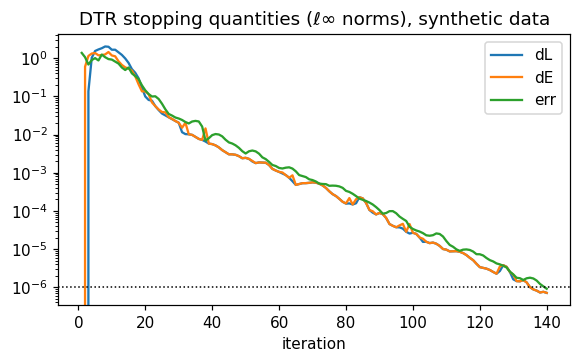

In [12]:
rng = np.random.default_rng(SEED)
n, n3, r = 100, 20, 5
X0 = tprod(rng.standard_normal((n, r, n3)) / np.sqrt(n), rng.standard_normal((r, n, n3)) / np.sqrt(n))
E0 = np.zeros_like(X0)
supp = rng.random((n, n)) < 0.1
E0[supp] = rng.choice([-1.0, 1.0], (supp.sum(), n3))
X_syn = X0 + E0


def synth_job(name):
    t0 = time.perf_counter()
    L, E, h = dtr(X_syn, history=True, **VARIANTS[name])
    return name, L, E, h, time.perf_counter() - t0


syn = run_parallel(synth_job, list(VARIANTS))
display(pd.DataFrame([{'method': nm, 'rel. error L': f'{np.linalg.norm(L - X0) / np.linalg.norm(X0):.2e}',
                       'rel. error E': f'{np.linalg.norm(E - E0) / np.linalg.norm(E0):.2e}',
                       'tubal rank L': tubal_rank(L, 1e-6), 'iterations': len(h), 'time (s)': sec}
                      for nm, L, E, h, sec in syn]).set_index('method'))

h = syn[-1][3]
h[['dL', 'dE', 'err']].plot(logy=True, figsize=(6, 3.2), title='DTR stopping quantities (ℓ∞ norms), synthetic data')
plt.axhline(1e-6, color='k', ls=':', lw=1); plt.xlabel('iteration'); plt.show()

TRPCA recovers $\mathcal X_0$ exactly, up to the stopping tolerance, but DTR-L and DTR **do not** with the paper's $\gamma_L=3$. The cause is the $\tau_L$ rule. With $r=5$ nonzero tubes out of $d=100$, $\tau_L=\gamma_L\,\mathrm{mean}_l\|\vec\sigma_l\|_2\approx(\gamma_L r/d)\,\|\vec\sigma_{\text{dominant}}\|_2$. The dominant tubes therefore get $w\approx1/(1+d/(\gamma_L r))\approx0.13$, so they are shrunk about 8× less than under TNN, and noise that enters them in early iterations is never removed. A larger $\gamma_L$ restores exact recovery:

In [13]:
def synth_gamma_job(args):
    name, g = args
    L, _ = dtr(X_syn, gamma_L=g, **VARIANTS[name])
    return dict(method=name, gamma_L=g, rel_err=np.linalg.norm(L - X0) / np.linalg.norm(X0))


res = run_parallel(synth_gamma_job, [(nm, g) for nm in ('DTR-L', 'DTR') for g in (3, 10, 30, 100)])
display(pd.DataFrame(res).pivot(index='gamma_L', columns='method', values='rel_err').map('{:.2e}'.format)
        .rename_axis(columns='rel. error of L'))

rel. error of L,DTR,DTR-L
gamma_L,,
3,8.93e-01,8.84e-01
10,4.11e-07,3.97e-07
30,1.14e-07,1.21e-07
100,3.96e-07,4.14e-07


## 6. Color image recovery (paper §4.1)

Protocol from the paper: BSDS500, 10% of the pixel positions replaced by values from $[0,255]$, with all three channels corrupted at the same positions (tube noise). We use $\lambda=1/\sqrt{3\max(d_1,d_2)}$, $\gamma_L=3$, $\gamma_E=10^3$, and report PSNR in dB over the whole image.

### 6.1 Six example images (Fig. 6, Tab. 2)

The paper does not say which six BSD images it uses. We take the first six test images in file order, so the per-image numbers are not directly comparable to Tab. 2, but the gap between TRPCA and DTR is.

In [27]:
def recover_job(job):
    """Worker: run DTR / a variant on job['X'] with job['kw']; returns PSNR, wall time (measured while
    other workers run, so only comparable within a batch) and, if job['keep'], the clipped estimate.
    'W_noise' is the mean T2L1 weight (for the job's gamma_E) on the truly corrupted tubes job['mask'],
    or on all nonzero tubes of E if no mask is given."""
    t0 = time.perf_counter()
    L, E = dtr(job['X'], **job['kw'])
    out = {k: v for k, v in job.items() if k not in ('X', 'ref', 'kw', 'keep', 'mask')}
    tubes = np.linalg.norm(E, axis=2)
    W = structure_weights(tubes, job['kw'].get('gamma_E', 1e3))
    sel = job['mask'] if 'mask' in job else tubes > 0
    out.update(psnr=psnr(L, job['ref']), time=time.perf_counter() - t0,
               W_noise=W[sel].mean() if sel.any() else np.nan)
    if job.get('keep'):
        out['L'] = np.clip(L, 0, 1)
    return out


def make_jobs(items, methods, keep=False, **extra):
    """items: iterable of (key, clean, noisy); methods: {name: dtr kwargs}."""
    return [dict(key=k, method=m, X=Xn, ref=ref, kw=kw, keep=keep, **extra)
            for k, ref, Xn in items for m, kw in methods.items()]

In [28]:
rng = np.random.default_rng(SEED)
ex_items, ex_masks = [], []
for f in EXAMPLES:
    ref = load_image(f)
    Xn, mask = tube_corrupt(ref, 0.10, rng)
    ex_items.append((f.stem, ref, Xn))
    ex_masks.append(mask)
IMG_METHODS = {m: VARIANTS[m] for m in ('TRPCA', 'DTR')}

t0 = time.time()
ex_res = run_parallel(recover_job, make_jobs(ex_items, IMG_METHODS, keep=True))
print(f'{len(ex_res)} runs in {time.time() - t0:.0f} s')
ex_df = pd.DataFrame(ex_res)
tab2 = ex_df.pivot(index='key', columns='method', values='psnr').loc[[f.stem for f in EXAMPLES], list(IMG_METHODS)]
tab2.insert(0, 'observed', [psnr(Xn, ref) for _, ref, Xn in ex_items])
tab2['gain DTR-TRPCA'] = tab2.DTR - tab2.TRPCA
tab2.index = [f'{i + 1}: {k}' for i, k in enumerate(tab2.index)]
PAPER_TAB2 = pd.DataFrame({'paper TRPCA': [31.05, 33.95, 28.25, 25.49, 27.12, 29.54],
                           'paper DTR': [34.31, 37.13, 32.19, 29.42, 30.16, 33.40]}, index=tab2.index)
PAPER_TAB2['paper gain'] = PAPER_TAB2['paper DTR'] - PAPER_TAB2['paper TRPCA']
display(pd.concat([tab2, PAPER_TAB2], axis=1))

12 runs in 107 s


,observed,TRPCA,DTR,gain DTR-TRPCA,paper TRPCA,paper DTR,paper gain
1: 100007,18.11,35.45,37.19,1.74,31.05,34.31,3.26
2: 100039,18.86,27.11,28.67,1.56,33.95,37.13,3.18
3: 100099,19.41,35.39,38.19,2.80,28.25,32.19,3.94
4: 10081,19.12,30.11,33.28,3.17,25.49,29.42,3.93
5: 101027,17.38,26.02,27.04,1.03,27.12,30.16,3.04
6: 101084,17.76,24.85,26.52,1.66,29.54,33.40,3.86


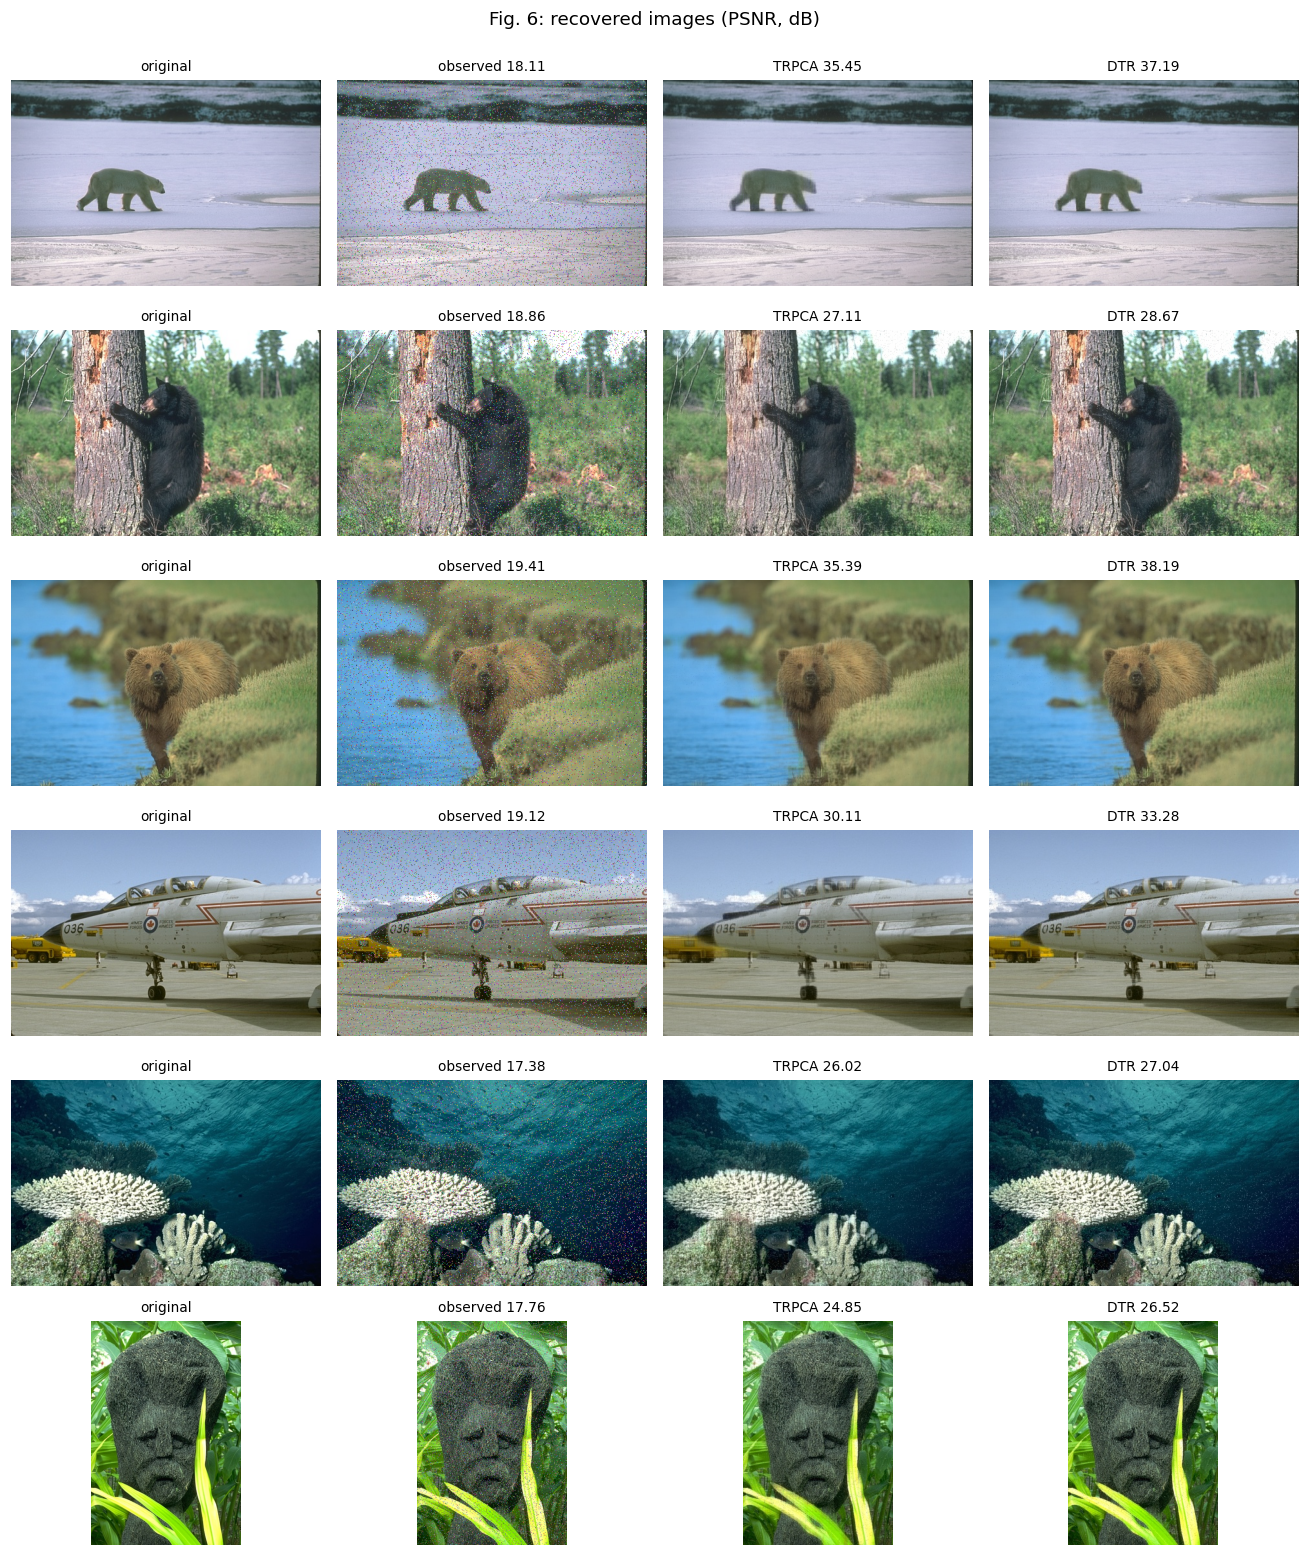

In [16]:
est = {(r['key'], r['method']): r['L'] for r in ex_res}
fig, axes = plt.subplots(len(ex_items), 4, figsize=(12, 2.35 * len(ex_items)))
for row, (key, ref, Xn) in zip(axes, ex_items):
    panels = [('original', ref), (f'observed {psnr(Xn, ref):.2f}', Xn)] + \
             [(f'{m} {psnr(est[key, m], ref):.2f}', est[key, m]) for m in IMG_METHODS]
    for ax, (title, im) in zip(row, panels):
        ax.imshow(np.clip(im, 0, 1)); ax.set_title(title, fontsize=9); ax.axis('off')
plt.suptitle('Fig. 6: recovered images (PSNR, dB)', y=1.0); plt.tight_layout(); plt.show()

### 6.2 BSD averages (Tab. 3)

The paper averages over all 500 images. By default we take the first `N_PER_SPLIT` images of each split; set it to `None` for the full benchmark, about 25× longer. Times are wall-clock while other workers share the CPU, so only the ratio between methods is meaningful.

In [17]:
N_PER_SPLIT = 20
rng = np.random.default_rng(SEED + 1)
bsd_items = []
for split in ('train', 'val', 'test'):
    for f in sorted((bsds / split).glob('*.jpg'))[:N_PER_SPLIT]:
        ref = load_image(f)
        bsd_items.append((f'{split}/{f.stem}', ref, tube_corrupt(ref, 0.10, rng)[0]))

t0 = time.time()
bsd_res = pd.DataFrame(run_parallel(recover_job, make_jobs(bsd_items, IMG_METHODS)))
print(f'{len(bsd_res)} runs in {time.time() - t0:.0f} s')
bsd_res['split'] = bsd_res.key.str.split('/').str[0]
tab3 = bsd_res.pivot_table(index='method', columns='split', values='psnr')[['train', 'val', 'test']]
tab3['all'] = bsd_res.groupby('method').psnr.mean()
tab3['avg time (s)'] = bsd_res.groupby('method').time.mean()
tab3.columns = [f'{c} ({N_PER_SPLIT})' if c in ('train', 'val', 'test') else c for c in tab3.columns]
PAPER_TAB3 = pd.DataFrame({'paper train (200)': [29.11, 31.14], 'paper val (100)': [28.72, 30.53],
                           'paper test (200)': [28.63, 30.70], 'paper all (500)': [28.84, 30.84],
                           'paper time (s)': [5.13, 6.68]}, index=['TRPCA', 'DTR'])
display(pd.concat([tab3.loc[['TRPCA', 'DTR']], PAPER_TAB3], axis=1))
wins = bsd_res.pivot(index='key', columns='method', values='psnr')
print(f'DTR beats TRPCA on {(wins.DTR > wins.TRPCA).sum()} / {len(wins)} images '
      f'(mean gain {(wins.DTR - wins.TRPCA).mean():.2f} dB)')

120 runs in 331 s


,train (20),val (20),test (20),all,avg time (s),paper train (200),paper val (100),paper test (200),paper all (500),paper time (s)
TRPCA,29.77,28.94,29.81,29.51,32.24,29.11,28.72,28.63,28.84,5.13
DTR,31.92,30.89,31.85,31.55,32.51,31.14,30.53,30.70,30.84,6.68


DTR beats TRPCA on 60 / 60 images (mean gain 2.05 dB)


### 6.3 Corruption ratio 10–50% (Tab. 4)

The paper uses all 100 BSDval images. We use the first `N_RATIO_IMAGES`. The two ablation variants are included so that any change with the corruption level can be traced to T2NN (DTR-L) or to T2L1 (DTR-E).

In [18]:
N_RATIO_IMAGES = 10
RATIOS = (0.1, 0.2, 0.3, 0.4, 0.5)
rng = np.random.default_rng(SEED + 2)
ratio_jobs = []
for f in sorted((bsds / 'val').glob('*.jpg'))[:N_RATIO_IMAGES]:
    ref = load_image(f)
    for ratio in RATIOS:
        ratio_jobs += make_jobs([(f.stem, ref, tube_corrupt(ref, ratio, rng)[0])], VARIANTS, ratio=ratio)

t0 = time.time()
ratio_res = pd.DataFrame(run_parallel(recover_job, ratio_jobs))
print(f'{len(ratio_res)} runs in {time.time() - t0:.0f} s')
tab4 = ratio_res.pivot_table(index='method', columns='ratio', values='psnr').loc[list(VARIANTS)]
tab4.columns = [f'{int(100 * c)}%' for c in tab4.columns]
PAPER_TAB4 = pd.DataFrame([[28.73, 26.07, 23.27, 20.66, 18.27], [31.14, 28.10, 24.46, 20.68, 19.53]],
                          index=['paper TRPCA', 'paper DTR'], columns=tab4.columns)
display(pd.concat([tab4, PAPER_TAB4]))

200 runs in 571 s


,10%,20%,30%,40%,50%
TRPCA,28.68,26.14,23.04,20.21,17.75
DTR-L,30.51,25.85,20.99,16.92,14.08
DTR-E,28.67,26.16,23.07,20.23,17.77
DTR,30.53,25.91,21.03,16.96,14.10
paper TRPCA,28.73,26.07,23.27,20.66,18.27
paper DTR,31.14,28.10,24.46,20.68,19.53


## 7. Hyperspectral image restoration (paper §4.2, Fig. 7)

The paper uses PaviaU (610×340, first 100 bands), with 10% of the pixels corrupted across all bands. If `data/PaviaU.mat` exists (the usual `paviaU` variable), it is used. Otherwise a synthetic cube stands in: four abundance maps taken from a natural image, linearly mixed with four smooth Gaussian spectra. It is approximately low tubal rank, like a real HSI, but the PSNR values are **not** comparable to the paper's.

synthetic HSI: (200, 200, 64), observed PSNR 18.84 dB


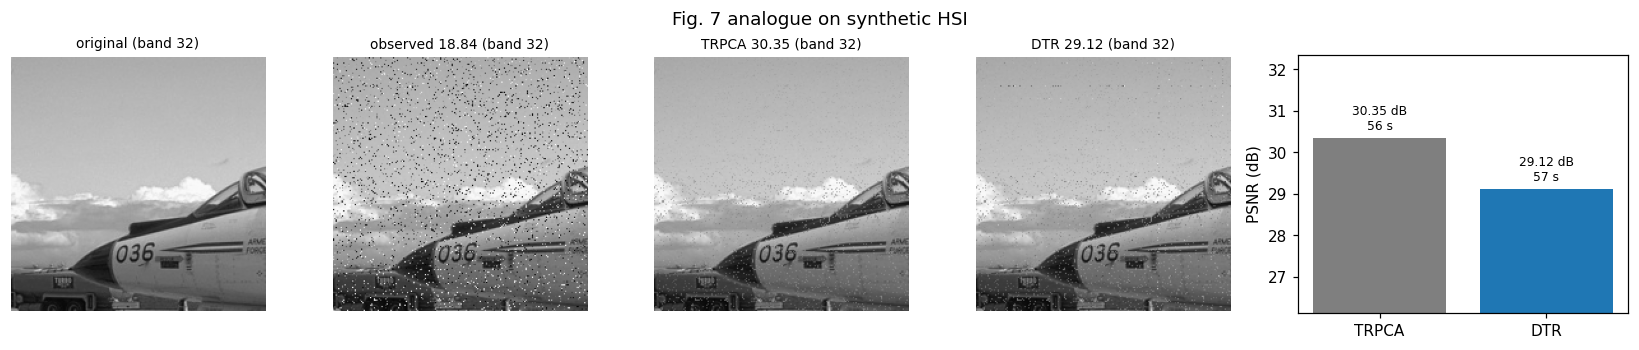

In [19]:
hsi_path = DATA_DIR / 'PaviaU.mat'
if hsi_path.exists():
    from scipy.io import loadmat
    cube = loadmat(hsi_path)['paviaU'][:, :, :100].astype(float)
    hsi_name = 'PaviaU'
else:
    base = load_image(EXAMPLES[3])[:200, :200]
    abund = np.stack([base[..., 0], base[..., 1], base[..., 2], base.mean(-1) ** 2], axis=-1)
    bands = np.linspace(0, 1, 64)
    spectra = np.stack([np.exp(-((bands - c) / 0.18) ** 2) for c in (0.15, 0.4, 0.65, 0.9)])
    cube = abund @ spectra
    hsi_name = 'synthetic HSI'
cube = (cube - cube.min()) / (cube.max() - cube.min())
Xh, _ = tube_corrupt(cube, 0.10, np.random.default_rng(SEED + 3))
print(f'{hsi_name}: {cube.shape}, observed PSNR {psnr(Xh, cube):.2f} dB')

hsi_res = run_parallel(recover_job, make_jobs([('hsi', cube, Xh)], IMG_METHODS, keep=True))
band = cube.shape[2] // 2
fig, ax = plt.subplots(1, 5, figsize=(15, 3.2), gridspec_kw={'width_ratios': [1, 1, 1, 1, 1.3]})
for a, (title, im) in zip(ax, [('original', cube), (f'observed {psnr(Xh, cube):.2f}', Xh)] +
                         [(f"{r['method']} {r['psnr']:.2f}", r['L']) for r in hsi_res]):
    a.imshow(im[:, :, band], vmin=0, vmax=1); a.set_title(f'{title} (band {band})', fontsize=9); a.axis('off')
ax[4].bar([r['method'] for r in hsi_res], [r['psnr'] for r in hsi_res], color=['tab:gray', 'tab:blue'])
for i, r in enumerate(hsi_res):
    ax[4].text(i, r['psnr'] + 0.2, f"{r['psnr']:.2f} dB\n{r['time']:.0f} s", ha='center', fontsize=8)
ax[4].set(ylabel='PSNR (dB)', ylim=(min(r['psnr'] for r in hsi_res) - 3, max(r['psnr'] for r in hsi_res) + 2))
plt.suptitle(f'Fig. 7 analogue on {hsi_name}'); plt.tight_layout(); plt.show()

## 8. Video denoising (paper §4.3, Tab. 5, Fig. 8) and ablation (§4.4, Tab. 6)

Protocol: the first 100 frames of each QCIF sequence, as a $144\times176\times100$ grayscale (luma) tensor. 10% of the pixel positions are replaced by random values in **every** frame, so the noise forms tubes along time. All four variants run here with the paper's parameters, which covers both Tab. 5 and the ablation in Tab. 6.

In [20]:
VIDEOS = ('akiyo', 'claire', 'container', 'news')
N_FRAMES = 100
rng = np.random.default_rng(SEED + 4)
vid_items, vid_masks = [], {}
for v in VIDEOS:
    ref = read_y4m(ensure_yuv(v), N_FRAMES)
    Xn, vid_masks[v] = tube_corrupt(ref, 0.10, rng)
    vid_items.append((v, ref, Xn))
vid_ref = {k: ref for k, ref, _ in vid_items}
vid_obs = {k: Xn for k, _, Xn in vid_items}

t0 = time.time()
vid_res = run_parallel(recover_job, make_jobs(vid_items, VARIANTS, keep=True), n_jobs=min(N_JOBS, 8))
print(f'{len(vid_res)} runs in {time.time() - t0:.0f} s')
vid_df = pd.DataFrame(vid_res).drop(columns='L')
vid_est = {(r['key'], r['method']): r['L'] for r in vid_res}

tab5 = vid_df.pivot(index='method', columns='key', values='psnr').loc[['TRPCA', 'DTR'], list(VIDEOS)]
tab5['avg time (s)'] = vid_df.groupby('method').time.mean()
PAPER_TAB5 = pd.DataFrame([[30.24, 30.12, 28.49, 26.01, 15.19], [33.57, 35.12, 31.85, 29.39, 26.64]],
                          index=['paper TRPCA', 'paper DTR'], columns=tab5.columns)
print('Tab. 5 (PSNR, dB)'); display(pd.concat([tab5, PAPER_TAB5]))

16 runs in 172 s
Tab. 5 (PSNR, dB)


key,akiyo,claire,container,news,avg time (s)
TRPCA,27.07,25.77,26.89,23.93,72.73
DTR,26.08,24.83,26.16,23.68,75.73
paper TRPCA,30.24,30.12,28.49,26.01,15.19
paper DTR,33.57,35.12,31.85,29.39,26.64


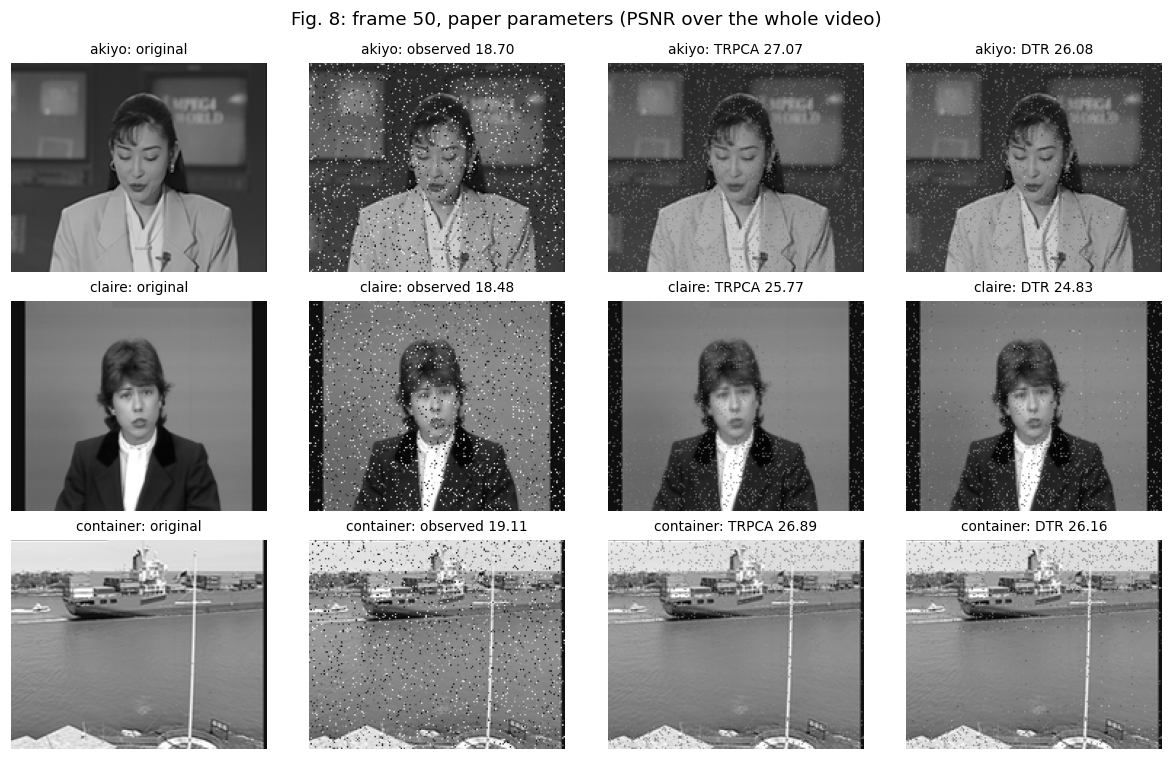

Tab. 6 ablation (PSNR, dB), paper parameters


,akiyo,claire,container,paper akiyo,paper claire,paper container
TRPCA,27.07,25.77,26.89,30.24,30.12,28.49
DTR-L,26.04,24.80,26.12,30.80,30.59,29.16
DTR-E,27.11,25.81,26.92,32.80,33.75,30.75
DTR,26.08,24.83,26.16,33.57,35.12,31.85


In [21]:
fig, axes = plt.subplots(3, 4, figsize=(11, 7))
fr = N_FRAMES // 2
for row, v in zip(axes, VIDEOS[:3]):
    panels = [('original', vid_ref[v]), (f'observed {psnr(vid_obs[v], vid_ref[v]):.2f}', vid_obs[v])] + \
             [(f'{m} {psnr(vid_est[v, m], vid_ref[v]):.2f}', vid_est[v, m]) for m in ('TRPCA', 'DTR')]
    for ax, (title, im) in zip(row, panels):
        ax.imshow(im[:, :, fr], vmin=0, vmax=1); ax.set_title(f'{v}: {title}', fontsize=9); ax.axis('off')
plt.suptitle(f'Fig. 8: frame {fr}, paper parameters (PSNR over the whole video)'); plt.tight_layout(); plt.show()

tab6 = vid_df.pivot(index='method', columns='key', values='psnr').loc[list(VARIANTS), list(VIDEOS[:3])]
PAPER_TAB6 = pd.DataFrame([[30.24, 30.12, 28.49], [30.80, 30.59, 29.16], [32.80, 33.75, 30.75], [33.57, 35.12, 31.85]],
                          index=list(VARIANTS), columns=[f'paper {v}' for v in VIDEOS[:3]])
print('Tab. 6 ablation (PSNR, dB), paper parameters'); display(pd.concat([tab6, PAPER_TAB6], axis=1))

**Where does the error come from?** The table below splits the PSNR of the Akiyo estimate into the corrupted pixel positions (10%) and the clean ones (90%). The corruption is at fixed positions, so the temporal mean of each noise tube looks like a static speckle pattern. The low-rank term can absorb that pattern into the static background more cheaply than the ℓ1 term can pay for it.

In [22]:
def split_psnr(L, ref, mask):
    return pd.Series({'corrupted pixels': psnr(L[mask], ref[mask]), 'clean pixels': psnr(L[~mask], ref[~mask]),
                      'all': psnr(L, ref)})


display(pd.DataFrame({m: split_psnr(vid_est['akiyo', m], vid_ref['akiyo'], vid_masks['akiyo']) for m in VARIANTS}).T)

,corrupted pixels,clean pixels,all
TRPCA,17.43,37.56,27.07
DTR-L,16.15,41.80,26.04
DTR-E,17.48,37.55,27.11
DTR,16.19,41.78,26.08


## 9. Parameter analysis (paper §4.4, Fig. 9) and γ_E sensitivity

Fig. 9 sweeps $\gamma_L\in[1,4]$ (with $\gamma_E=10^3$) and $\gamma_E\in[10^2,10^6]$ (with $\gamma_L=3$) on one color image. We repeat that sweep and extend the $\gamma_E$ range downwards. We also run the same $\gamma_E$ sweep on the Akiyo video.

The reason for the extension: $\tau_E=\gamma_E\cdot\mathrm{mean}_{ij}\|\mathcal E(i,j,:)\|_2$. At convergence a fraction $p\approx0.1$ of the tubes is nonzero with comparable norms, so $\|\mathcal E(i,j,:)\|_2/\tau_E\approx 1/(\gamma_E p)$ and $W_{ij}\approx 1/(1+1/(\gamma_E p))$. For $\gamma_E=10^3$ that gives $W\approx0.99$: T2L1 is then essentially the plain ℓ1 norm.

23 runs in 120 s


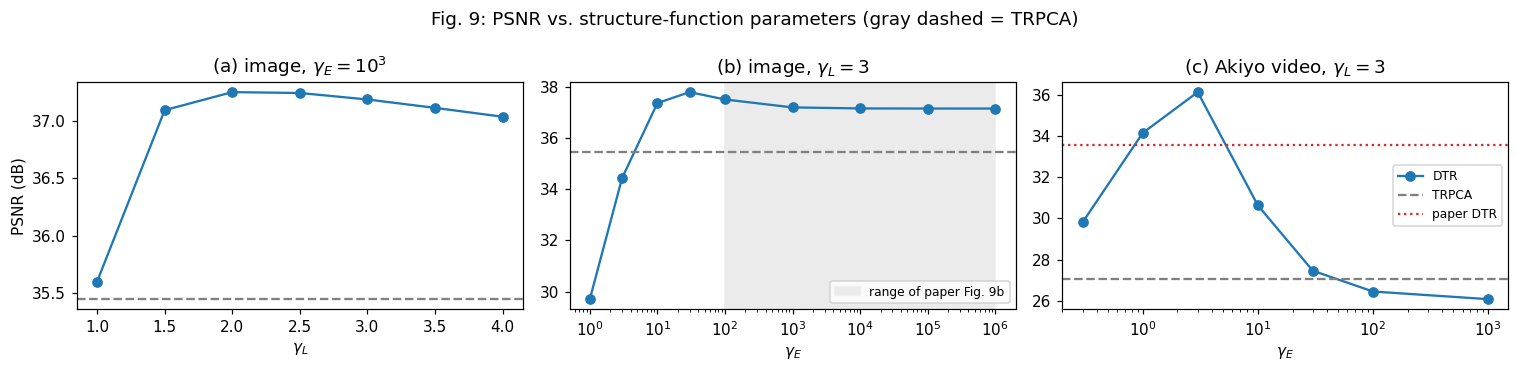

psnr        W_noise      
key        akiyo  image   akiyo image
gamma_E                              
0.3        29.81    NaN    0.04   NaN
1.0        34.15  29.71    0.10  0.12
3.0        36.13  34.43    0.25  0.28
10.0       30.63  37.36    0.52  0.54
30.0       27.46  37.78    0.77  0.77
100.0      26.45  37.50    0.92  0.92
1000.0     26.08  37.19    0.99  0.99
10000.0      NaN  37.15     NaN  1.00
100000.0     NaN  37.14     NaN  1.00
1000000.0    NaN  37.14     NaN  1.00

In [23]:
GAMMA_L_GRID = (1, 1.5, 2, 2.5, 3, 3.5, 4)
GAMMA_E_GRID = (1, 3, 10, 30, 1e2, 1e3, 1e4, 1e5, 1e6)
VIDEO_GAMMA_E_GRID = (0.3, 1, 3, 10, 30, 100, 1e3)

img_job = dict(key='image', method='DTR', X=ex_items[0][2], ref=ex_items[0][1], mask=ex_masks[0])
vid_job = dict(key='akiyo', method='DTR', X=vid_obs['akiyo'], ref=vid_ref['akiyo'], mask=vid_masks['akiyo'])
sweep_jobs = [dict(img_job, sweep='gamma_L', value=g, kw=dict(gamma_L=g, gamma_E=1e3)) for g in GAMMA_L_GRID]
sweep_jobs += [dict(img_job, sweep='gamma_E', value=g, kw=dict(gamma_L=3, gamma_E=g)) for g in GAMMA_E_GRID]
sweep_jobs += [dict(vid_job, sweep='gamma_E', value=g, kw=dict(gamma_L=3, gamma_E=g)) for g in VIDEO_GAMMA_E_GRID]

t0 = time.time()
sweep = pd.DataFrame(run_parallel(recover_job, sweep_jobs, n_jobs=min(N_JOBS, 10)))
print(f'{len(sweep_jobs)} runs in {time.time() - t0:.0f} s')

img_trpca = tab2.TRPCA.iloc[0]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
s = sweep[(sweep.key == 'image') & (sweep.sweep == 'gamma_L')]
ax[0].plot(s.value, s.psnr, 'o-'); ax[0].set(title='(a) image, $\\gamma_E=10^3$', xlabel='$\\gamma_L$', ylabel='PSNR (dB)')
s = sweep[(sweep.key == 'image') & (sweep.sweep == 'gamma_E')].sort_values('value')
ax[1].semilogx(s.value, s.psnr, 'o-'); ax[1].axvspan(1e2, 1e6, color='0.92', zorder=0, label='range of paper Fig. 9b')
ax[1].set(title='(b) image, $\\gamma_L=3$', xlabel='$\\gamma_E$'); ax[1].legend(fontsize=8)
s = sweep[sweep.key == 'akiyo'].sort_values('value')
ax[2].semilogx(s.value, s.psnr, 'o-', label='DTR')
ax[2].axhline(tab5.loc['TRPCA', 'akiyo'], color='gray', ls='--', label='TRPCA')
ax[2].axhline(PAPER_TAB5.loc['paper DTR', 'akiyo'], color='tab:red', ls=':', label='paper DTR')
ax[2].set(title='(c) Akiyo video, $\\gamma_L=3$', xlabel='$\\gamma_E$'); ax[2].legend(fontsize=8)
for a in ax[:2]:
    a.axhline(img_trpca, color='gray', ls='--')
plt.suptitle('Fig. 9: PSNR vs. structure-function parameters (gray dashed = TRPCA)'); plt.tight_layout(); plt.show()

display(sweep[sweep.sweep == 'gamma_E'].pivot(index='value', columns='key', values=['psnr', 'W_noise'])
        .rename_axis('gamma_E').round(3))

`W_noise` is the mean T2L1 weight $W_{ij}$ on the truly corrupted tubes, evaluated at convergence. A value close to 1 means T2L1 penalises the noise like the plain ℓ1 norm.

We now pick the best $\gamma_E$ from the Akiyo sweep and rerun the video experiments with it on all four sequences. This choice is **tuned on one of the test videos**. It is shown to explain the gap to Tabs. 5–6, not as a fair benchmark number.

gamma_E selected on Akiyo: 3.0


8 runs in 89 s


,akiyo,claire,container,news,mean
TRPCA,27.07,25.77,26.89,23.93,25.92
DTR-L,26.04,24.80,26.12,23.64,25.15
DTR-E,27.11,25.81,26.92,23.96,25.95
DTR,26.08,24.83,26.16,23.68,25.18
DTR (gE=3),36.13,37.47,33.21,29.99,34.20
DTR-E (gE=3),33.35,33.73,31.13,27.47,31.42
paper TRPCA,30.24,30.12,28.49,26.01,28.71
paper DTR-L,30.80,30.59,29.16,NaN,NaN
paper DTR-E,32.80,33.75,30.75,NaN,NaN
paper DTR,33.57,35.12,31.85,29.39,32.48


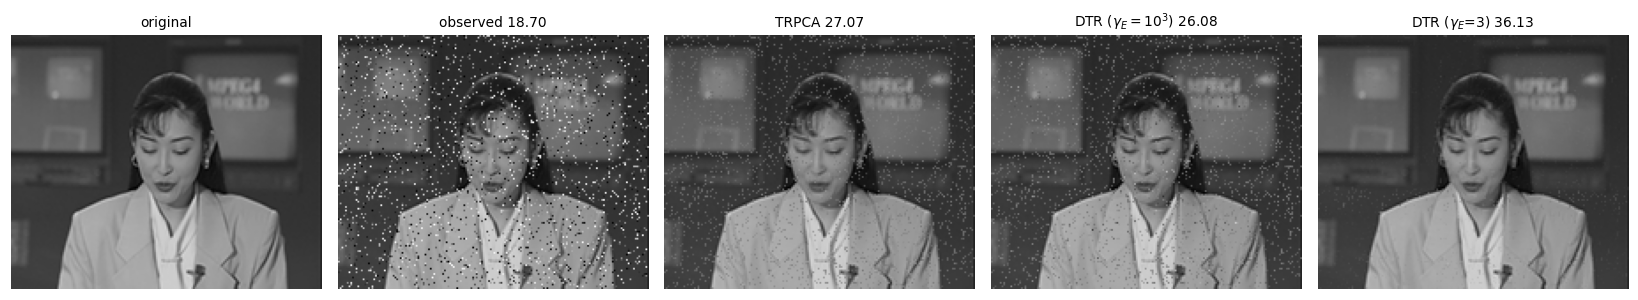

,corrupted pixels,clean pixels,all
TRPCA,17.43,37.56,27.07
DTR,16.19,41.78,26.08
DTR (gE=3),28.73,39.13,36.13


In [24]:
s = sweep[sweep.key == 'akiyo']
VIDEO_GAMMA_E = float(s.loc[s.psnr.idxmax(), 'value'])
print('gamma_E selected on Akiyo:', VIDEO_GAMMA_E)

t0 = time.time()
tuned = run_parallel(recover_job, make_jobs(vid_items, {f'{m} (gE={VIDEO_GAMMA_E:g})': dict(VARIANTS[m], gamma_E=VIDEO_GAMMA_E)
                                                        for m in ('DTR-E', 'DTR')}, keep=True), n_jobs=min(N_JOBS, 8))
print(f'{len(tuned)} runs in {time.time() - t0:.0f} s')
vid_est.update({(r['key'], r['method']): r['L'] for r in tuned})
tuned_df = pd.DataFrame(tuned).drop(columns='L')
vid_all = pd.concat([vid_df, tuned_df]).pivot(index='method', columns='key', values='psnr')[list(VIDEOS)]
vid_all['mean'] = vid_all.mean(axis=1)
paper_rows = pd.DataFrame([[30.24, 30.12, 28.49, 26.01], [30.80, 30.59, 29.16, np.nan],
                           [32.80, 33.75, 30.75, np.nan], [33.57, 35.12, 31.85, 29.39]],
                          index=[f'paper {m}' for m in VARIANTS], columns=list(VIDEOS))
paper_rows['mean'] = paper_rows.mean(axis=1, skipna=False)
display(pd.concat([vid_all.loc[list(VARIANTS) + [m for m in vid_all.index if 'gE=' in m]], paper_rows]))

v, fr = 'akiyo', N_FRAMES // 2
key_t = f'DTR (gE={VIDEO_GAMMA_E:g})'
fig, ax = plt.subplots(1, 5, figsize=(15, 2.8))
for a, (title, im) in zip(ax, [('original', vid_ref[v]), ('observed', vid_obs[v]), ('TRPCA', vid_est[v, 'TRPCA']),
                               ('DTR ($\\gamma_E=10^3$)', vid_est[v, 'DTR']), (f'DTR ($\\gamma_E$={VIDEO_GAMMA_E:g})', vid_est[v, key_t])]):
    p = '' if title == 'original' else f' {psnr(im, vid_ref[v]):.2f}'
    a.imshow(im[:, :, fr], vmin=0, vmax=1); a.set_title(title + p, fontsize=9); a.axis('off')
plt.tight_layout(); plt.show()
display(pd.DataFrame({m: split_psnr(vid_est['akiyo', m], vid_ref['akiyo'], vid_masks['akiyo'])
                      for m in ('TRPCA', 'DTR', key_t)}).T)

## 10. Background modeling (paper §4.5, Fig. 10)

The paper uses CAVIAR1 from the SBI dataset: 610 color frames resized to 64×96. Each video becomes a $(\text{pixels})\times3\times(\text{frames})$ tensor, so tubes run along time and $d=\min(d_1,d_2)=3$. Matrix RPCA uses the $(\text{pixels}\cdot3)\times(\text{frames})$ matrix.

CAVIAR1 is not available here, so we use **Hall Monitor**: a static corridor camera with people walking, 300 frames downsampled 2× to 72×88. The tensor is $6336\times3\times300$. There is no ground truth, so the comparison is qualitative, as in the paper.

background-modeling tensor: (6336, 3, 300)


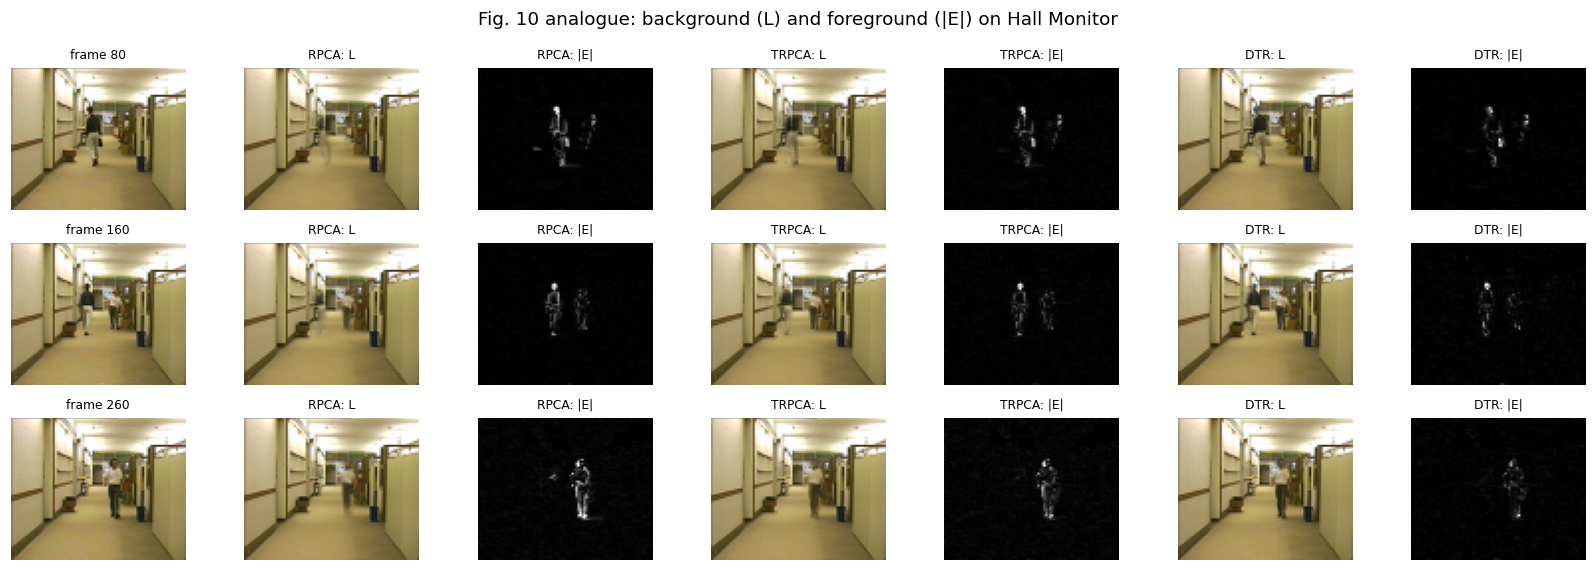

,time (s),foreground density (|E|>0.02),background temporal std
method,,,
RPCA,90.95,0.10,9.20e-03
TRPCA,51.25,0.10,1.20e-02
DTR,48.34,0.04,2.00e-02


In [25]:
def rpca(M, lam=None, mu=1e-2, rho=1.1, mu_max=1e10, tol=1e-6, max_iter=500):
    """Matrix RPCA (nuclear norm + l1, Candes et al.) with the same ADMM scheme as Algorithm 1."""
    lam = 1.0 / np.sqrt(max(M.shape)) if lam is None else lam
    L, E, N = np.zeros_like(M), np.zeros_like(M), np.zeros_like(M)
    for _ in range(max_iter):
        U, s, Vh = np.linalg.svd(M - E - N / mu, full_matrices=False)
        L_new = (U * np.maximum(s - 1.0 / mu, 0.0)) @ Vh
        K = M - L_new - N / mu
        E_new = np.sign(K) * np.maximum(np.abs(K) - lam / mu, 0.0)
        R = L_new + E_new - M
        N = N + mu * R
        done = max(np.abs(L_new - L).max(), np.abs(E_new - E).max(), np.abs(R).max()) < tol
        L, E, mu = L_new, E_new, min(rho * mu, mu_max)
        if done:
            break
    return L, E


frames = read_y4m(ensure_yuv('hall_monitor'), rgb=True)                 # 144 x 176 x 3 x T
H0, W0, _, T = frames.shape
frames = frames.reshape(H0 // 2, 2, W0 // 2, 2, 3, T).mean(axis=(1, 3))  # 72 x 88 x 3 x T
h, w_, _, T = frames.shape
X_bg = frames.reshape(h * w_, 3, T)
print('background-modeling tensor:', X_bg.shape)


def bg_job(name):
    t0 = time.perf_counter()
    if name == 'RPCA':
        L, E = rpca(frames.reshape(-1, T))
    else:
        L, E = dtr(X_bg, **VARIANTS[name])
    return name, L.reshape(h, w_, 3, T), E.reshape(h, w_, 3, T), time.perf_counter() - t0


bg = run_parallel(bg_job, ['RPCA', 'TRPCA', 'DTR'])
SHOW = (80, 160, 260)
fig, axes = plt.subplots(len(SHOW), 1 + 2 * len(bg), figsize=(15, 1.75 * len(SHOW)))
for row, t in zip(axes, SHOW):
    row[0].imshow(frames[:, :, :, t]); row[0].set_title(f'frame {t}', fontsize=8)
    for i, (name, L, E, _) in enumerate(bg):
        fg = np.abs(E[:, :, :, t]).sum(-1)
        row[1 + 2 * i].imshow(np.clip(L[:, :, :, t], 0, 1)); row[1 + 2 * i].set_title(f'{name}: L', fontsize=8)
        row[2 + 2 * i].imshow(fg, vmin=0, vmax=max(fg.max(), 1e-6)); row[2 + 2 * i].set_title(f'{name}: |E|', fontsize=8)
for a in axes.ravel():
    a.axis('off')
plt.suptitle('Fig. 10 analogue: background (L) and foreground (|E|) on Hall Monitor'); plt.tight_layout(); plt.show()
display(pd.DataFrame([{'method': nm, 'time (s)': sec,
                       'foreground density (|E|>0.02)': (np.abs(E) > 0.02).mean(),
                       'background temporal std': L.std(axis=3).mean()} for nm, L, E, sec in bg]).set_index('method'))

*Foreground density* is the fraction of entries assigned to the sparse part. *Background temporal std* measures how much the recovered background still flickers or keeps ghosts of the walkers; lower is a cleaner static background.

## 11. Summary: paper vs. this implementation

In [26]:
summary = pd.DataFrame({
    'paper TRPCA': [PAPER_TAB3.loc['TRPCA', 'paper all (500)'], PAPER_TAB5.loc['paper TRPCA', list(VIDEOS)].mean()],
    'paper DTR': [PAPER_TAB3.loc['DTR', 'paper all (500)'], PAPER_TAB5.loc['paper DTR', list(VIDEOS)].mean()],
    'ours TRPCA': [tab3.loc['TRPCA', 'all'], vid_all.loc['TRPCA', 'mean']],
    'ours DTR (paper params)': [tab3.loc['DTR', 'all'], vid_all.loc['DTR', 'mean']],
    f'ours DTR (gamma_E={VIDEO_GAMMA_E:g})': [np.nan, vid_all.loc[f'DTR (gE={VIDEO_GAMMA_E:g})', 'mean']],
}, index=[f'BSD color images, 10% tube noise ({3 * N_PER_SPLIT} imgs here)', 'YUV videos, 10% tube noise (mean of 4)'])
display(summary)

,paper TRPCA,paper DTR,ours TRPCA,ours DTR (paper params),ours DTR (gamma_E=3)
"BSD color images, 10% tube noise (60 imgs here)",28.84,30.84,29.51,31.55,NaN
"YUV videos, 10% tube noise (mean of 4)",28.71,32.48,25.92,25.18,34.2


### Observations from the saved run (default settings)

**Reproduced**
- **Preliminaries (§2).** The t-product, t-SVD, tubal rank and TNN identities hold to machine precision ($\le10^{-14}$).
- **Color images (Tabs. 2–3).** With the paper's parameters, DTR beats TRPCA on **60 / 60** BSD images, by +2.05 dB on average. The paper reports +2.0 dB over all 500. Our absolute values are about 0.7 dB higher for both methods (29.51 / 31.55 vs. 28.84 / 30.84), plausibly because we use a 60-image subset.

**Not reproduced with the stated parameters**
- **Corruption ratio (Tab. 4).**
  - At 10% corruption, DTR gains +1.85 dB over TRPCA. From 20% on it falls below TRPCA: 21.03 vs 23.04 dB at 30%, and 14.10 vs 17.75 dB at 50%. The paper reports DTR ahead at every ratio.
  - DTR-L tracks DTR and DTR-E tracks TRPCA, so the drop comes from the **T2NN weighting** ($\gamma_L=3$).
- **Synthetic exact recovery (§5).**
  - TRPCA recovers the tubal-rank-5 tensor exactly (rel. error $3.7\times10^{-7}$). DTR and DTR-L do not ($0.89$).
  - Exact recovery returns for $\gamma_L\ge10$. The rule $\tau_L=\gamma_L\cdot\mathrm{mean}$ over all $d$ tubes leaves the few dominant tubes almost unpenalised.
- **Video (Tabs. 5–6) and HSI (Fig. 7).**
  - With $\gamma_E=10^3$, the T2L1 weights on the corrupted tubes are 0.99 at convergence, so T2L1 is effectively the ℓ1 norm.
  - As a result, DTR-E equals TRPCA (27.11 vs 27.07 dB on Akiyo). DTR is slightly *below* TRPCA on every video (mean 25.18 vs 25.92) and on the synthetic HSI (29.12 vs 30.35).
  - TRPCA keeps clean pixels well (37.6 dB on Akiyo) but fails on the corrupted positions (17.4 dB). The temporal mean of the fixed-position noise is absorbed into the low-rank background.
- **γ_E is the decisive parameter.**
  - On Akiyo, PSNR peaks at $\gamma_E=3$. With that value, DTR reaches a **34.20 dB** mean over the four videos, against 32.48 in the paper, and DTR-E reaches 31.42. On Akiyo the corrupted-pixel PSNR rises from 16.2 to 28.7 dB.
  - The paper's video gains are therefore consistent with an effective $\gamma_E$ of order 1–10 under the stated definition of $\tau_E$, not $10^3$.
  - This value is tuned on a test video.
- **TRPCA itself is about 2.8 dB below the paper's TRPCA on video** (25.92 vs 28.71), and t-CTV shows a similar gap in notebook 02. TRPCA has no γ parameters, so the paper's video protocol probably differs from ours in some unreported detail, such as the noise values or the PSNR definition.
- **Parameter analysis (Fig. 9).**
  - On the example image, PSNR is flat (37.1–37.5 dB) across the paper's range $\gamma_E\in[10^2,10^6]$, whereas the paper's Fig. 9b varies over that range. The image optimum is around $\gamma_E=30$ (37.8 dB).
  - $\gamma_L$ has a broad optimum at 2–3 on this image.
- **Background modeling (Fig. 10, Hall Monitor instead of CAVIAR1).**
  - DTR assigns far fewer entries to the foreground than RPCA or TRPCA (4% vs 10%).
  - Its background keeps more temporal variation, with faint walker residue (std 0.020 vs 0.012 / 0.009).
  - There is no ground truth, and this sequence does not visibly support the paper's claim that DTR is more accurate here.

**Not implemented:** ETRPCA, BTRTF, t-SWP, SRPCA, BTPCA and SNN. PaviaU and CAVIAR1 were not downloadable, so stand-ins were used.